# 02 - SVM
Trabalho Prático de Mineração de Dados, Grupo 8

Base: Predict Students' Dropout and Academic Success

### 1. Carregamento dos dados e limpeza inicial

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

local_path = Path("../../data/data.csv")
source = local_path if local_path.exists() else "https://raw.githubusercontent.com/DaviComerio/trabalho-mineracao-de-dados/main/data/data.csv"
dataset = pd.read_csv(source, sep=";")
dataset.columns = dataset.columns.str.strip()

X = dataset.drop(columns=["Target"])
y = dataset["Target"]
dataset.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### 2. Pré-processamento e validação cruzada estratificada

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

colunas_categoricas = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]
colunas_binarias = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]
colunas_numericas = [
    col for col in X.columns
    if col not in colunas_categoricas and col not in colunas_binarias
]

encoder_categorico = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
preprocessador = ColumnTransformer(
    transformers=[
        ("cat", encoder_categorico, colunas_categoricas),
        ("num", StandardScaler(), colunas_numericas),
        ("bin", "passthrough", colunas_binarias),
    ]
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def avaliar(modelo, X, y):
    metricas = {"acc": [], "prec": [], "rec": [], "f1": []}
    y_true_all, y_pred_all = [], []
    for tr, te in skf.split(X, y):
        X_tr = preprocessador.fit_transform(X.iloc[tr])
        X_te = preprocessador.transform(X.iloc[te])
        modelo.fit(X_tr, y.iloc[tr])
        pred = modelo.predict(X_te)
        metricas["acc"].append(accuracy_score(y.iloc[te], pred))
        metricas["prec"].append(precision_score(y.iloc[te], pred, average="macro"))
        metricas["rec"].append(recall_score(y.iloc[te], pred, average="macro"))
        metricas["f1"].append(f1_score(y.iloc[te], pred, average="macro"))
        y_true_all.extend(y.iloc[te]); y_pred_all.extend(pred)
    return metricas, y_true_all, y_pred_all

### 3. Treinamento e comparação de configurações do SVM

In [3]:
configs_svm = {
    "linear C=1":  SVC(kernel='linear', C=1),
    "rbf C=1":     SVC(kernel='rbf', C=1, gamma='scale'),
    "rbf C=10":    SVC(kernel='rbf', C=10, gamma='scale'),
    "poly C=1":    SVC(kernel='poly', C=1, gamma='scale'),
}

linhas, previsoes = [], {}
for nome, modelo in configs_svm.items():
    m, yt, yp = avaliar(modelo, X, y)
    previsoes[nome] = (yt, yp)
    linhas.append({"Modelo": "SVM",
                   "Config": nome,
                   "Acurácia": f"{np.mean(m['acc']):.4f} ± {np.std(m['acc']):.4f}",
                   "Acurácia_media": np.mean(m["acc"]),
                   "Acurácia_std": np.std(m["acc"]),
                   "Precisão_macro": np.mean(m["prec"]),
                   "Revocação_macro": np.mean(m["rec"]),
                   "F1_macro": np.mean(m["f1"]),
                   "F1_std": np.std(m["f1"])})
resumo_df = pd.DataFrame(linhas)
Path("../../resultados").mkdir(parents=True, exist_ok=True)
resumo_df.to_csv("../../resultados/svm_resultados.csv", index=False)

resumo = resumo_df[["Config", "Acurácia", "Precisão_macro", "Revocação_macro", "F1_macro"]].rename(columns={
    "Precisão_macro": "Precisão (macro)",
    "Revocação_macro": "Revocação (macro)",
    "F1_macro": "F1 (macro)",
})
resumo

,Config,Acurácia,Precisão (macro),Revocação (macro),F1 (macro)
0,linear C=1,0.7710 ± 0.0101,0.717164,0.685592,0.694568
1,rbf C=1,0.7703 ± 0.0055,0.723949,0.675665,0.687198
2,rbf C=10,0.7642 ± 0.0146,0.707104,0.688505,0.694567
3,poly C=1,0.7509 ± 0.0126,0.709648,0.645241,0.656962


### 4. Comparação gráfica das configurações

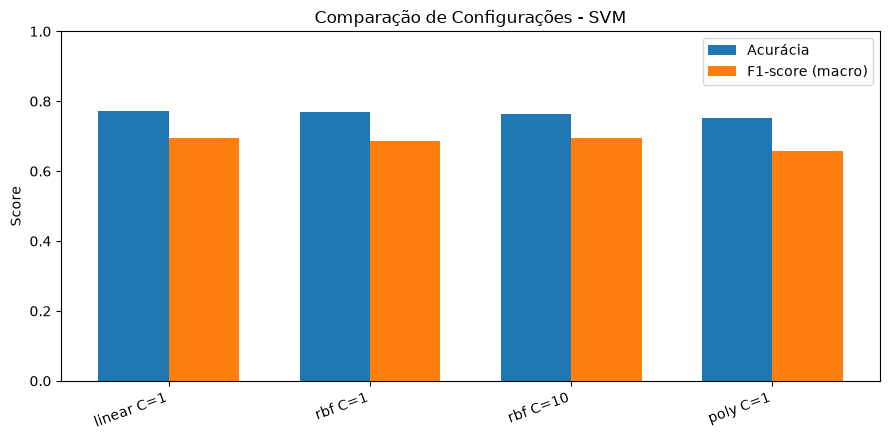

In [4]:
nomes = list(previsoes.keys())
acc_medias = [accuracy_score(previsoes[n][0], previsoes[n][1]) for n in nomes]
f1_medias = [f1_score(previsoes[n][0], previsoes[n][1], average="macro") for n in nomes]

x = np.arange(len(nomes))
largura = 0.35

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - largura/2, acc_medias, largura, label="Acurácia")
ax.bar(x + largura/2, f1_medias, largura, label="F1-score (macro)")
ax.set_xticks(x)
ax.set_xticklabels(nomes, rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Comparação de Configurações - SVM")
ax.legend()
plt.tight_layout()
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/comparacao_svm.png", dpi=300, bbox_inches="tight")
plt.show()

### 5. Matriz de confusão do melhor modelo

Melhor configuração: linear C=1
              precision    recall  f1-score   support

     Dropout       0.81      0.76      0.78      1421
    Enrolled       0.54      0.38      0.44       794
    Graduate       0.80      0.92      0.86      2209

    accuracy                           0.77      4424
   macro avg       0.72      0.69      0.69      4424
weighted avg       0.76      0.77      0.76      4424



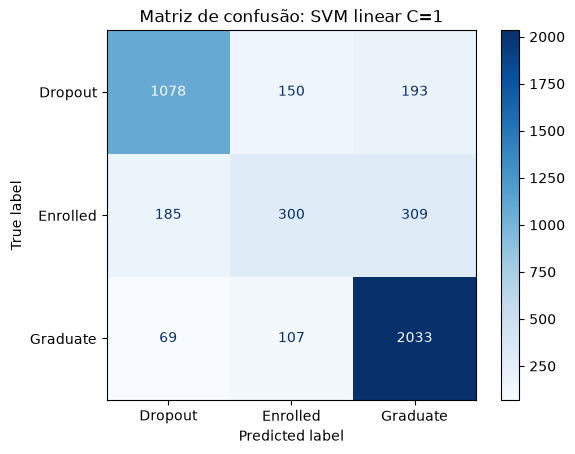

In [5]:
melhor = max(previsoes, key=lambda n: f1_score(previsoes[n][0], previsoes[n][1], average="macro"))
print(f"Melhor configuração: {melhor}")

yt, yp = previsoes[melhor]
print(classification_report(yt, yp))
ConfusionMatrixDisplay.from_predictions(yt, yp, cmap="Blues")
plt.title(f"Matriz de confusão: SVM {melhor}")
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/matriz_confusao_svm.png", dpi=300, bbox_inches="tight")
plt.show()